<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta6_g%C3%B6rev1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


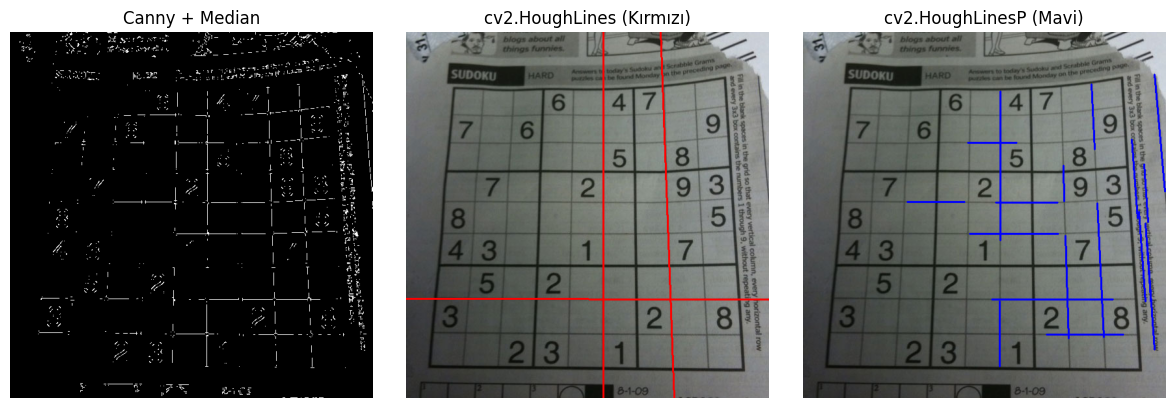

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/sudoku.png'
req = urllib.request.urlopen(url)
arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
img = cv2.imdecode(arr, cv2.IMREAD_COLOR)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 50, 150, apertureSize=3)

median_edges = cv2.medianBlur(edges, 3)

img_hough_std = img.copy()
lines_std = cv2.HoughLines(median_edges, 1, np.pi / 180, 150)

if lines_std is not None:
    for line in lines_std:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv2.line(img_hough_std, (x1, y1), (x2, y2), (0, 0, 255), 2)

img_hough_prob = img.copy()
lines_prob = cv2.HoughLinesP(median_edges, 1, np.pi / 180, threshold=80, minLineLength=50, maxLineGap=10)

if lines_prob is not None:
    for line in lines_prob:
        x1, y1, x2, y2 = line[0]
        cv2.line(img_hough_prob, (x1, y1), (x2, y2), (255, 0, 0), 2)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(median_edges, cmap='gray')
plt.title('Canny + Median')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(cv2.cvtColor(img_hough_std, cv2.COLOR_BGR2RGB))
plt.title('cv2.HoughLines (Kırmızı)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(cv2.cvtColor(img_hough_prob, cv2.COLOR_BGR2RGB))
plt.title('cv2.HoughLinesP (Mavi)')
plt.axis('off')

plt.tight_layout()
plt.show()